In [672]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [673]:
data = pd.read_csv("/kaggle/input/datasets/lava18/google-play-store-apps/googleplaystore.csv")
data.head(5)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [674]:
data.info()

# missing values are in -> Rating, Type, Content Rating, Current Ver, Android Ver

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [675]:
mask = data['Rating'].isna()


In [676]:
data[mask] = data[mask].fillna(data['Rating'].mean())


In [677]:
data.head(5)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [678]:
mask = data['Content Rating'].isna()
mask

0        False
1        False
2        False
3        False
4        False
         ...  
10836    False
10837    False
10838    False
10839    False
10840    False
Name: Content Rating, Length: 10841, dtype: bool

In [679]:
data[mask] = data[mask].fillna('Unknown')


In [680]:
data[mask]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,Unknown,"February 11, 2018",1.0.19,4.0 and up,Unknown


In [681]:
mask3 = data['Current Ver'].isna()
mask3

0        False
1        False
2        False
3        False
4        False
         ...  
10836    False
10837    False
10838    False
10839    False
10840    False
Name: Current Ver, Length: 10841, dtype: bool

In [682]:
data[mask3] = data[mask3].fillna('Unknown')

In [683]:
data['Android Ver'] = data['Android Ver'].isna().fillna('Unknown')

In [684]:
data[data['Android Ver'].isna()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


In [685]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          10841 non-null  float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10841 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10841 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10841 non-null  object 
 12  Android Ver     10841 non-null  bool   
dtypes: bool(1), float64(1), object(11)
memory usage: 1.0+ MB


In [686]:
data.head(5)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,False
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,False
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,False
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,False
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,False


In [687]:
# Convert Data Types: convert Installs and Price to numerical values).

data['Installs'].unique()

array(['10,000+', '500,000+', '5,000,000+', '50,000,000+', '100,000+',
       '50,000+', '1,000,000+', '10,000,000+', '5,000+', '100,000,000+',
       '1,000,000,000+', '1,000+', '500,000,000+', '50+', '100+', '500+',
       '10+', '1+', '5+', '0+', '0', 'Free'], dtype=object)

In [688]:
data['Installs'] = data['Installs'].str.replace(',','').str.replace('+','').str.replace('Free','0')

In [689]:
data['Installs'].unique()

array(['10000', '500000', '5000000', '50000000', '100000', '50000',
       '1000000', '10000000', '5000', '100000000', '1000000000', '1000',
       '500000000', '50', '100', '500', '10', '1', '5', '0'], dtype=object)

In [690]:
data['Installs'] = data['Installs'].astype(int)

In [691]:
data['Price'] = data['Price'].str.replace('Everyone','0').str.replace('$','')

In [692]:
data['Price'] = data['Price'].astype(float).astype(int)

In [693]:
data['Price'].unique()

array([  0,   4,   3,   6,   1,   2,   7,   5,   9,  10,  24,  11,  79,
        16,  14,  29,  12,  19,  15,  33,  74,  39,   8,  25, 399,  17,
       400,  13, 299, 379,  37,  18, 389,  46, 109, 154,  28, 200,  89,
        30, 394])

In [694]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          10841 non-null  float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  int64  
 6   Type            10841 non-null  object 
 7   Price           10841 non-null  int64  
 8   Content Rating  10841 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10841 non-null  object 
 12  Android Ver     10841 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(9)
memory usage: 1.0+ MB


In [695]:
data

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.100000,159,19M,10000,Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,False
1,Coloring book moana,ART_AND_DESIGN,3.900000,967,14M,500000,Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,False
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.700000,87510,8.7M,5000000,Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,False
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.500000,215644,25M,50000000,Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,False
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.300000,967,2.8M,100000,Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10836,Sya9a Maroc - FR,FAMILY,4.500000,38,53M,5000,Free,0,Everyone,Education,"July 25, 2017",1.48,False
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.000000,4,3.6M,100,Free,0,Everyone,Education,"July 6, 2018",1.0,False
10838,Parkinson Exercices FR,MEDICAL,4.193338,3,9.5M,1000,Free,0,Everyone,Medical,"January 20, 2017",1.0,False
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.500000,114,Varies with device,1000,Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,False


In [696]:
mask = data[['App','Category','Rating','Reviews','Size']].duplicated()

In [697]:
data = data.drop_duplicates(subset=['App','Category','Rating','Reviews','Size'])

In [698]:
data.head(2)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,10000,Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,False
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,500000,Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,False


In [699]:
data['Category'] = data['Category'].astype('category')

/tmp/ipykernel_49/745450692.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Category'] = data['Category'].astype('category')


In [700]:
data['Genres'].unique()

array(['Art & Design', 'Art & Design;Pretend Play',
       'Art & Design;Creativity', 'Art & Design;Action & Adventure',
       'Auto & Vehicles', 'Beauty', 'Books & Reference', 'Business',
       'Comics', 'Comics;Creativity', 'Communication', 'Dating',
       'Education;Education', 'Education', 'Education;Creativity',
       'Education;Music & Video', 'Education;Action & Adventure',
       'Education;Pretend Play', 'Education;Brain Games', 'Entertainment',
       'Entertainment;Music & Video', 'Entertainment;Brain Games',
       'Entertainment;Creativity', 'Events', 'Finance', 'Food & Drink',
       'Health & Fitness', 'House & Home', 'Libraries & Demo',
       'Lifestyle', 'Lifestyle;Pretend Play',
       'Adventure;Action & Adventure', 'Arcade', 'Casual', 'Card',
       'Casual;Pretend Play', 'Action', 'Strategy', 'Puzzle', 'Sports',
       'Music', 'Word', 'Racing', 'Casual;Creativity',
       'Casual;Action & Adventure', 'Simulation', 'Adventure', 'Board',
       'Trivia', 'Role 

In [701]:
data['Genres'] =  data['Genres'].str.replace('February 11, 2018', 'nan')
data

/tmp/ipykernel_49/1372458060.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Genres'] =  data['Genres'].str.replace('February 11, 2018', 'nan')


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.100000,159,19M,10000,Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,False
1,Coloring book moana,ART_AND_DESIGN,3.900000,967,14M,500000,Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,False
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.700000,87510,8.7M,5000000,Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,False
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.500000,215644,25M,50000000,Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,False
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.300000,967,2.8M,100000,Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10836,Sya9a Maroc - FR,FAMILY,4.500000,38,53M,5000,Free,0,Everyone,Education,"July 25, 2017",1.48,False
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.000000,4,3.6M,100,Free,0,Everyone,Education,"July 6, 2018",1.0,False
10838,Parkinson Exercices FR,MEDICAL,4.193338,3,9.5M,1000,Free,0,Everyone,Medical,"January 20, 2017",1.0,False
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.500000,114,Varies with device,1000,Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,False


In [702]:
data['Genres'] = data['Genres'].astype('category')
data

/tmp/ipykernel_49/4024850489.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Genres'] = data['Genres'].astype('category')


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.100000,159,19M,10000,Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,False
1,Coloring book moana,ART_AND_DESIGN,3.900000,967,14M,500000,Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,False
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.700000,87510,8.7M,5000000,Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,False
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.500000,215644,25M,50000000,Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,False
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.300000,967,2.8M,100000,Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10836,Sya9a Maroc - FR,FAMILY,4.500000,38,53M,5000,Free,0,Everyone,Education,"July 25, 2017",1.48,False
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.000000,4,3.6M,100,Free,0,Everyone,Education,"July 6, 2018",1.0,False
10838,Parkinson Exercices FR,MEDICAL,4.193338,3,9.5M,1000,Free,0,Everyone,Medical,"January 20, 2017",1.0,False
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.500000,114,Varies with device,1000,Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,False


In [703]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10356 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   App             10356 non-null  object  
 1   Category        10356 non-null  category
 2   Rating          10356 non-null  float64 
 3   Reviews         10356 non-null  object  
 4   Size            10356 non-null  object  
 5   Installs        10356 non-null  int64   
 6   Type            10356 non-null  object  
 7   Price           10356 non-null  int64   
 8   Content Rating  10356 non-null  object  
 9   Genres          10356 non-null  category
 10  Last Updated    10356 non-null  object  
 11  Current Ver     10356 non-null  object  
 12  Android Ver     10356 non-null  bool    
dtypes: bool(1), category(2), float64(1), int64(2), object(7)
memory usage: 926.6+ KB


In [704]:
data['Last Updated'] = pd.to_datetime(data['Last Updated'],format='mixed',errors='coerce')

/tmp/ipykernel_49/342755675.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Last Updated'] = pd.to_datetime(data['Last Updated'],format='mixed',errors='coerce')


In [705]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10356 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             10356 non-null  object        
 1   Category        10356 non-null  category      
 2   Rating          10356 non-null  float64       
 3   Reviews         10356 non-null  object        
 4   Size            10356 non-null  object        
 5   Installs        10356 non-null  int64         
 6   Type            10356 non-null  object        
 7   Price           10356 non-null  int64         
 8   Content Rating  10356 non-null  object        
 9   Genres          10356 non-null  category      
 10  Last Updated    10355 non-null  datetime64[ns]
 11  Current Ver     10356 non-null  object        
 12  Android Ver     10356 non-null  bool          
dtypes: bool(1), category(2), datetime64[ns](1), float64(1), int64(2), object(6)
memory usage: 926.6+ KB


# **DATA CLEANING DONE**

In [706]:
# 1. What is the average rating of apps in the dataset?

data['Rating'].mean().round(2)

# The average rating of apps in the dataset is -  4.19

np.float64(4.19)

In [707]:
# 2. How many unique categories of apps are there?

data['Category'].nunique()

# There are 34 unique categories of apps in the dataset.

34

In [708]:
# 3. What is the distribution of app sizes?

data = data.copy()

s = data['Size'].astype('string').str.strip()

data['Size'] = pd.to_numeric(s.str.replace(r'[MmKk]$', '', regex=True), errors='coerce')

data.loc[s.str.endswith(('k', 'K'), na=False), 'Size'] /= 1024

In [709]:
print(data['Size'].head(10))
print(data['Size'].dtype)
print(data['Size'].isnull().sum())

0    19.0
1    14.0
2     8.7
3    25.0
4     2.8
5     5.6
6    19.0
7    29.0
8    33.0
9     3.1
Name: Size, dtype: Float64
Float64
1527


In [710]:
print(data['Size'].isnull().sum())

1527


In [711]:
data['Size'] = pd.to_numeric(data['Size'], errors='coerce')

In [712]:
data['Size'].isnull().sum()

np.int64(1527)

In [713]:
print(data['Size'].dtype)
print(data['Size'].head(10))

Float64
0    19.0
1    14.0
2     8.7
3    25.0
4     2.8
5     5.6
6    19.0
7    29.0
8    33.0
9     3.1
Name: Size, dtype: Float64


In [714]:
data['Size'].dtype

Float64Dtype()

<Axes: ylabel='Frequency'>

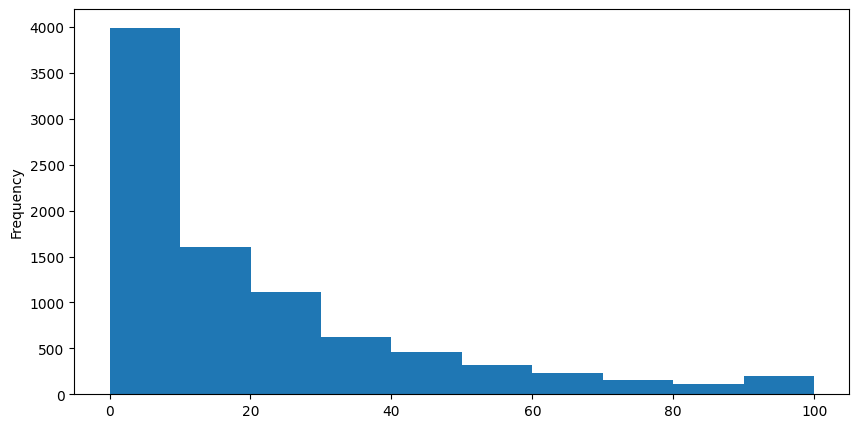

In [715]:
plt.figure(figsize=(10,5))

data['Size'].plot(kind='hist')

# pandas graph plotting function

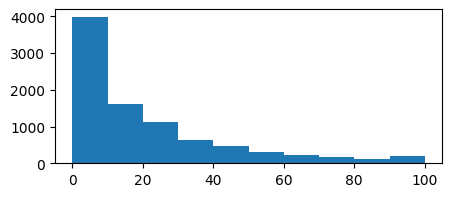

In [716]:
plt.figure(figsize=(5,2))

plt.hist(data['Size'])

plt.show()

# This function is for matplotlib to draw the graph.

In [717]:
# 4. How many free vs paid apps are there?

data['Type'].value_counts()

Type
Free        9589
Paid         765
4.193338       1
0              1
Name: count, dtype: int64

In [718]:
# 5. What is the most common content rating for apps?

data['Content Rating'].mode()



0    Everyone
Name: Content Rating, dtype: object

In [719]:
# 6. What are the top 5 most installed apps?

data[['Installs','App']].drop_duplicates(subset= 'App').sort_values(by = 'Installs', ascending= False).head(5)

,Installs,App
2808,1000000000,Google Photos
865,1000000000,Google Play Games
3117,1000000000,Maps - Navigate & Explore
391,1000000000,Skype - free IM & video calls
152,1000000000,Google Play Books


In [720]:
# 7. How many apps have a rating of 4.0 and above?

m6 = data['Rating']>=4
m6

0         True
1        False
2         True
3         True
4         True
         ...  
10836     True
10837     True
10838     True
10839     True
10840     True
Name: Rating, Length: 10356, dtype: bool

In [721]:
data[m6].shape[0]

8411

In [722]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10356 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             10356 non-null  object        
 1   Category        10356 non-null  category      
 2   Rating          10356 non-null  float64       
 3   Reviews         10356 non-null  object        
 4   Size            8829 non-null   Float64       
 5   Installs        10356 non-null  int64         
 6   Type            10356 non-null  object        
 7   Price           10356 non-null  int64         
 8   Content Rating  10356 non-null  object        
 9   Genres          10356 non-null  category      
 10  Last Updated    10355 non-null  datetime64[ns]
 11  Current Ver     10356 non-null  object        
 12  Android Ver     10356 non-null  bool          
dtypes: Float64(1), bool(1), category(2), datetime64[ns](1), float64(1), int64(2), object(5)
memory usage: 936.7+ KB

In [723]:
# 8. What is the average number of reviews for free vs paid apps?

data['Reviews'] = data['Reviews'].str.replace('M','e6').str.replace('K','e3').astype(float)

In [724]:
data[data['Type'].isin(['Free','Paid'])].groupby('Type')['Reviews'].mean().astype(int)

Type
Free    437443
Paid     11900
Name: Reviews, dtype: int64

In [725]:
# 9. What is the average app size for each category?

data = data.copy()

data.groupby('Category')['Size'].mean().dropna().round(2)

/tmp/ipykernel_49/21882699.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby('Category')['Size'].mean().dropna().round(2)


Category
ART_AND_DESIGN         12.37
AUTO_AND_VEHICLES      20.04
BEAUTY                  13.8
BOOKS_AND_REFERENCE    13.19
BUSINESS               13.91
COMICS                 13.48
COMMUNICATION          11.66
DATING                 15.83
EDUCATION              20.08
ENTERTAINMENT          22.64
EVENTS                 13.96
FAMILY                 27.93
FINANCE                17.94
FOOD_AND_DRINK         22.06
GAME                   44.13
HEALTH_AND_FITNESS     21.64
HOUSE_AND_HOME         15.97
LIBRARIES_AND_DEMO     11.08
LIFESTYLE              14.86
MAPS_AND_NAVIGATION    16.61
MEDICAL                19.38
NEWS_AND_MAGAZINES     12.65
PARENTING              22.51
PERSONALIZATION        11.29
PHOTOGRAPHY            16.83
PRODUCTIVITY           12.87
SHOPPING               15.85
SOCIAL                 16.88
SPORTS                 24.18
TOOLS                   8.78
TRAVEL_AND_LOCAL       24.52
VIDEO_PLAYERS          16.08
WEATHER                13.12
Name: Size, dtype: Float64

In [726]:
# 10. How many apps were last updated in 2018?

data = data.copy()

m8 = data['Last Updated'].dt.year == 2018
m8.sum()


np.int64(6932)

In [727]:
# Also shown the app name last updated in year 2018

data[m8][['App','Last Updated']]


,App,Last Updated
0,Photo Editor & Candy Camera & Grid & ScrapBook,2018-01-07
1,Coloring book moana,2018-01-15
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",2018-08-01
3,Sketch - Draw & Paint,2018-06-08
4,Pixel Draw - Number Art Coloring Book,2018-06-20
...,...,...
10826,Frim: get new friends on local chat rooms,2018-03-23
10827,Fr Agnel Ambarnath,2018-06-13
10831,payermonstationnement.fr,2018-06-13
10837,Fr. Mike Schmitz Audio Teachings,2018-07-06


# **Medium-Level Questions: Start**

In [728]:
# 1. What is the correlation between the number of installs and the app rating?

data = data.drop(index=10472).copy()

data['Installs'].corr(data['Rating'])

np.float64(0.050472694043325016)

In [729]:
data[data['Rating']>5]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver


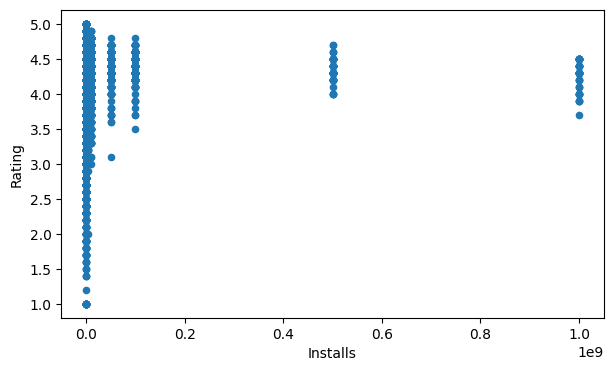

In [730]:
data.plot(kind='scatter', x= 'Installs', y= 'Rating',figsize=(7,4))

plt.show()

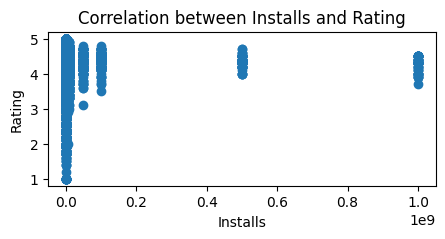

In [731]:
plt.figure(figsize=(5,2))

plt.scatter(data['Installs'],data['Rating'])

plt.xlabel('Installs')
plt.ylabel('Rating')
plt.title('Correlation between Installs and Rating')

plt.show()

In [732]:
# 2. Which app categories have the highest average rating?

data = data.copy()

data.groupby('Category')['Rating'].mean().round(2).sort_values(ascending=False)

/tmp/ipykernel_49/3439650610.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby('Category')['Rating'].mean().round(2).sort_values(ascending=False)


Category
EDUCATION              4.37
EVENTS                 4.36
ART_AND_DESIGN         4.35
BOOKS_AND_REFERENCE    4.31
PERSONALIZATION        4.31
PARENTING              4.28
GAME                   4.28
BEAUTY                 4.26
HEALTH_AND_FITNESS     4.25
SHOPPING               4.25
SOCIAL                 4.25
WEATHER                4.24
SPORTS                 4.22
PRODUCTIVITY           4.20
MEDICAL                4.19
FAMILY                 4.19
AUTO_AND_VEHICLES      4.19
LIBRARIES_AND_DEMO     4.18
PHOTOGRAPHY            4.18
HOUSE_AND_HOME         4.17
FOOD_AND_DRINK         4.17
COMMUNICATION          4.16
COMICS                 4.16
BUSINESS               4.14
FINANCE                4.14
NEWS_AND_MAGAZINES     4.14
ENTERTAINMENT          4.14
TRAVEL_AND_LOCAL       4.11
LIFESTYLE              4.11
TOOLS                  4.07
MAPS_AND_NAVIGATION    4.07
VIDEO_PLAYERS          4.07
DATING                 4.01
1.9                     NaN
Name: Rating, dtype: float64

In [733]:
# 3. How does the price of an app affect its average rating?

data = data.copy()

data.groupby(['Price','Type',])['Rating'].mean().sort_values(ascending=False)

Price  Type    
18     Paid        4.600000
79     Paid        4.600000
19     Paid        4.412382
14     Paid        4.369334
7      Paid        4.366667
11     Paid        4.366667
24     Paid        4.348335
3      Paid        4.317895
2      Paid        4.279540
5      Paid        4.269497
1      Paid        4.269483
0      Paid        4.268677
13     Paid        4.246669
12     Paid        4.225000
6      Paid        4.216080
37     Paid        4.200000
154    Paid        4.193338
200    Paid        4.193338
0      4.193338    4.193338
394    Paid        4.193338
28     Paid        4.193338
30     Paid        4.193338
89     Paid        4.193338
46     Paid        4.193338
74     Paid        4.193338
109    Paid        4.193338
25     Paid        4.193338
9      Paid        4.193335
0      Free        4.183925
29     Paid        4.178668
4      Paid        4.163644
16     Paid        4.100000
39     Paid        4.096669
10     Paid        4.075000
15     Paid        4.050000
399 

In [734]:
# 3. How does the price of an app affect its average rating?

data = data.copy()

data = data.dropna(subset= ['Price','Type','Rating'])

data = data[data['Type'].isin(['Free','Paid'])]

data.groupby(['Price','Type',])['Rating'].mean().round(2).sort_values(ascending=False)


Price  Type
79     Paid    4.60
18     Paid    4.60
19     Paid    4.41
11     Paid    4.37
7      Paid    4.37
14     Paid    4.37
24     Paid    4.35
3      Paid    4.32
2      Paid    4.28
0      Paid    4.27
1      Paid    4.27
5      Paid    4.27
13     Paid    4.25
6      Paid    4.22
12     Paid    4.22
37     Paid    4.20
200    Paid    4.19
109    Paid    4.19
394    Paid    4.19
28     Paid    4.19
30     Paid    4.19
89     Paid    4.19
46     Paid    4.19
74     Paid    4.19
25     Paid    4.19
9      Paid    4.19
154    Paid    4.19
29     Paid    4.18
0      Free    4.18
4      Paid    4.16
16     Paid    4.10
39     Paid    4.10
10     Paid    4.08
15     Paid    4.05
399    Paid    4.02
8      Paid    3.86
299    Paid    3.80
17     Paid    3.75
400    Paid    3.60
389    Paid    3.60
33     Paid    3.50
379    Paid    2.90
Name: Rating, dtype: float64

In [735]:
data.groupby('Type')['Rating'].mean()

Type
Free    4.183925
Paid    4.247957
Name: Rating, dtype: float64

In [736]:
import matplotlib.pyplot as plt
import matplotlib.pyplot as mpl
import importlib

importlib.reload(mpl)

plt = mpl

In [737]:
print(type(plt.figure))
print(type(mpl.figure))

<class 'function'>
<class 'function'>


Object `ratings` not found.


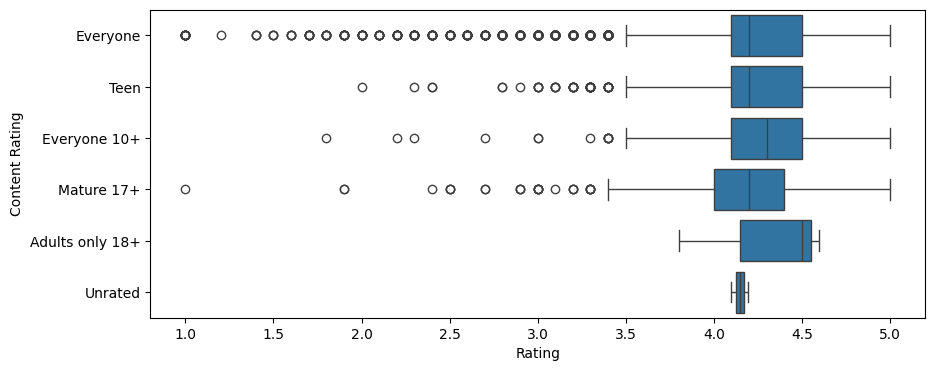

In [738]:
4. What is the distribution of app ratings across different content ratings?

plt.figure(figsize=(10,4))

sns.boxplot(data=data, x= 'Rating', y = 'Content Rating')

plt.show()

In [739]:
# 5. Which genres have the most apps with over 1 million installs?

data = data.copy()

m2 = data['Installs'] >= 1000000
m2

data[m2].groupby('Genres').size().sort_values(ascending=False)

/tmp/ipykernel_49/1775172539.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data[m2].groupby('Genres').size().sort_values(ascending=False)


Genres
Tools                                287
Action                               237
Photography                          213
Communication                        191
Productivity                         180
                                    ... 
Role Playing;Education                 0
Travel & Local;Action & Adventure      0
Strategy;Education                     0
Trivia;Education                       0
nan                                    0
Length: 120, dtype: int64

In [740]:
# 6. How frequently do apps get updated? Calculate the average time between updates.


Temp = data[['App','Last Updated']].sort_values(by= ['App','Last Updated'])
Temp.groupby('App')['Last Updated'].diff().mean()

Timedelta('7 days 21:12:24.827586206')

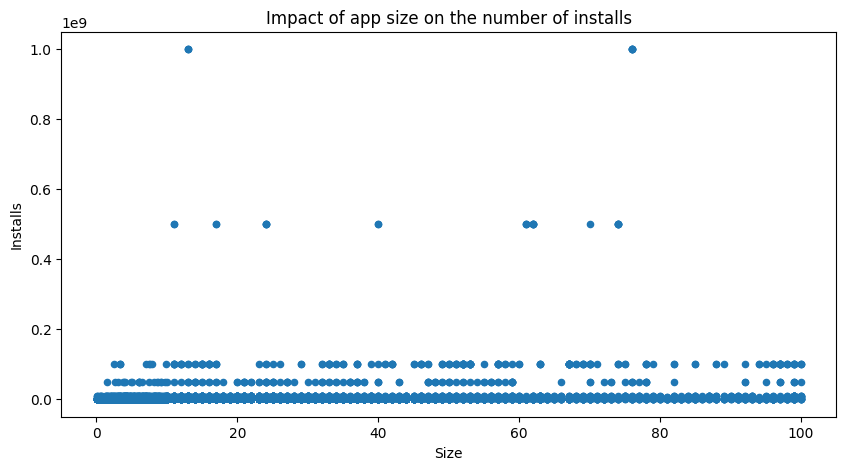

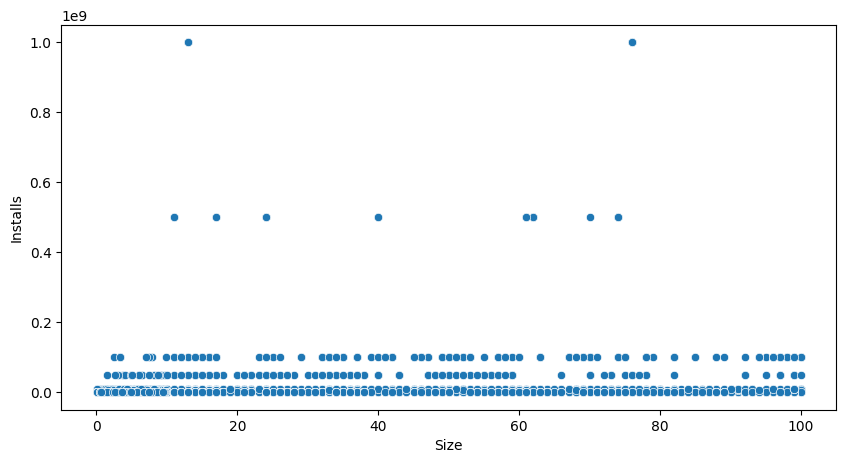

In [741]:
# 7. What is the impact of app size on the number of installs?

data.plot(kind='scatter', x ='Size',y = 'Installs',figsize=(10,5),title='Impact of app size on the number of installs')

plt.show()

plt.figure(figsize=(10,5))

sns.scatterplot(data=data, x='Size', y= 'Installs')

plt.show()

In [742]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10354 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             10354 non-null  object        
 1   Category        10354 non-null  category      
 2   Rating          10354 non-null  float64       
 3   Reviews         10354 non-null  float64       
 4   Size            8829 non-null   Float64       
 5   Installs        10354 non-null  int64         
 6   Type            10354 non-null  object        
 7   Price           10354 non-null  int64         
 8   Content Rating  10354 non-null  object        
 9   Genres          10354 non-null  category      
 10  Last Updated    10354 non-null  datetime64[ns]
 11  Current Ver     10354 non-null  object        
 12  Android Ver     10354 non-null  bool          
dtypes: Float64(1), bool(1), category(2), datetime64[ns](1), float64(2), int64(2), object(4)
memory usage: 936.6+ KB

In [743]:
# 8. Which apps have the highest number of reviews, and what are their ratings?

data.sort_values(by='Reviews',ascending=False)[['App','Reviews', 'Rating']]

,App,Reviews,Rating
2544,Facebook,78158306.0,4.100000
3943,Facebook,78128208.0,4.100000
336,WhatsApp Messenger,69119316.0,4.400000
3904,WhatsApp Messenger,69109672.0,4.400000
2604,Instagram,66577446.0,4.500000
...,...,...,...
10798,Word Search Tab 1 FR,0.0,4.193338
4218,D+H Reaction Wall,0.0,4.193338
7652,Co-Dependents Anonymous,0.0,4.193338
7168,Best Design CD Ideas,0.0,4.193338


In [744]:
# 9. How does the content rating distribution differ between free and paid apps?

Temp = data.groupby(['Content Rating','Type'])['Type'].count().unstack(fill_value=0)
Temp


Type,Free,Paid
Content Rating,,
Adults only 18+,3,0
Everyone,7718,662
Everyone 10+,344,32
Mature 17+,428,19
Teen,1094,52
Unrated,2,0


In [745]:
pd.crosstab(data['Content Rating'],data['Type'],normalize='columns').mul(100).round(2).astype(str)+'%'

Type,Free,Paid
Content Rating,,
Adults only 18+,0.03%,0.0%
Everyone,80.49%,86.54%
Everyone 10+,3.59%,4.18%
Mature 17+,4.46%,2.48%
Teen,11.41%,6.8%
Unrated,0.02%,0.0%


In [746]:
# 10. What are the top 5 categories with the most installs?

data = data.copy()

data.groupby('Category')['Installs'].sum().sort_values(ascending=False).head(5)


/tmp/ipykernel_49/131452249.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby('Category')['Installs'].sum().sort_values(ascending=False).head(5)


Category
GAME             31544024415
COMMUNICATION    24152276251
SOCIAL           12513867902
PRODUCTIVITY     12463091369
TOOLS            11442771915
Name: Installs, dtype: int64

In [747]:
# 10. What are the top 5 categories with the most installs?

data = data.copy()

data.groupby('Category',as_index=False)['Installs'].sum().sort_values(by='Installs',ascending=False).head(5)

/tmp/ipykernel_49/1231264533.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  data.groupby('Category',as_index=False)['Installs'].sum().sort_values(by='Installs',ascending=False).head(5)


,Category,Installs
15,GAME,31544024415
7,COMMUNICATION,24152276251
28,SOCIAL,12513867902
26,PRODUCTIVITY,12463091369
30,TOOLS,11442771915


# **Advanced-Level Questions:**

In [748]:
# 1. What are the top 10 apps with the highest ratings, and how do their number of reviews and installs compare?

data[['App','Rating','Reviews','Installs']].sort_values(by=['Rating'],ascending=False).head(10) 



,App,Rating,Reviews,Installs
8327,The Divine Feminine App: the DF App,5.0,8.0,1000
10837,Fr. Mike Schmitz Audio Teachings,5.0,4.0,100
6494,BM speed test,5.0,1.0,10
9455,EJ messenger,5.0,1.0,10
7865,CT Brain Interpretation,5.0,3.0,500
7896,CT Checkout,5.0,1.0,50
7895,Dine In CT - Food Delivery,5.0,4.0,1000
7842,CS & IT Interview Questions,5.0,43.0,1000
7805,CR Tracker for Chests,5.0,6.0,50
5268,AJ Rafael Music Lessons,5.0,1.0,10


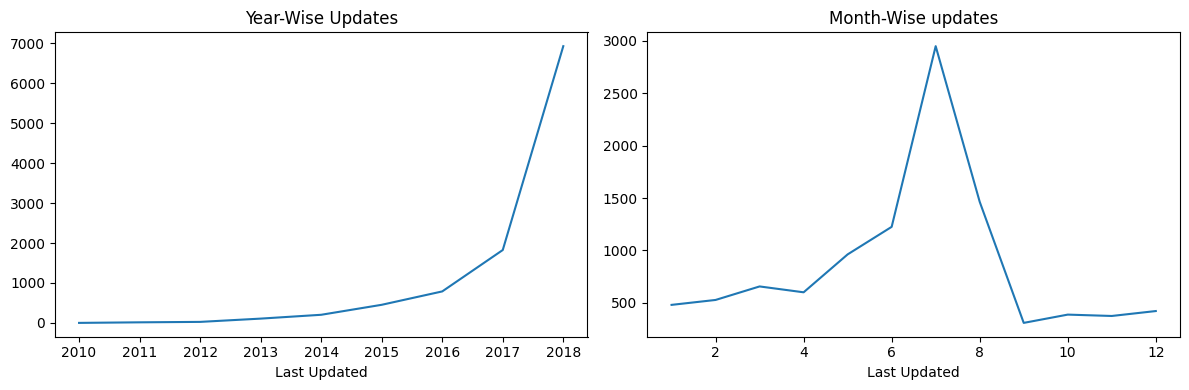

In [749]:
# 2. Analyze the trend of app updates over time. Are there any noticeable patterns or seasonal trends?

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

data['Last Updated'].dt.year.value_counts().sort_index().plot(kind='line')
plt.title('Year-Wise Updates')

plt.subplot(1, 2, 2)

data['Last Updated'].dt.month.value_counts().sort_index().plot(kind='line')
plt.title('Month-Wise updates')

plt.tight_layout()
plt.show()

# Noticeable patterns or seasonal trends is major apps are updated in 2018 and in month of July. 

In [750]:
# 3. How does the average rating of apps change with the number of installs? Create a binned analysis.

bins = [0, 10000, 100000, 1000000, float('inf')]

data['Install Group'] = pd.cut(data['Installs'], bins=bins)

data.groupby('Install Group', observed=False)['Rating'].mean()

Install Group
(0.0, 10000.0]           4.139915
(10000.0, 100000.0]      4.096502
(100000.0, 1000000.0]    4.207022
(1000000.0, inf]         4.311115
Name: Rating, dtype: float64

In [751]:
# 4. Perform sentiment analysis on app reviews (if review text is available) to determine the common themes in high and low-rated apps.

# Hi Mentor Please tell me how to do this question as i am not getting how to code this question. 

In [752]:
# 5. What is the relationship between app genre and user ratings? Are certain genres consistently rated higher or lower?

# Highest rated genres

data.groupby('Genres',observed=True)['Rating'].agg(['mean','median']).sort_values(by='mean',ascending=False).head()

,mean,median
Genres,,
Board;Pretend Play,4.8,4.8
Comics;Creativity,4.8,4.8
Health & Fitness;Education,4.7,4.7
Puzzle;Education,4.6,4.6
Strategy;Action & Adventure,4.6,4.6


In [753]:
# 5. What is the relationship between app genre and user ratings? Are certain genres consistently rated higher or lower?

# Lowest rated genres
data.groupby('Genres', observed=True)['Rating'].agg(['mean', 'median']).sort_values(by='mean', ascending=True).head()

,mean,median
Genres,,
Parenting;Brain Games,3.800000,3.8
Art & Design;Pretend Play,3.900000,3.9
Health & Fitness;Action & Adventure,3.900000,3.9
Educational,3.915316,4.0
Educational;Creativity,3.960000,4.2
